# Image Forgery Detection Using Classical Image Processing Techniques
## Phase 2 — Progress Report

**Group J:** Smit Patel (2479966), Ananay Gupta (2618966)
**Course:** EDS 6364 — Digital Image Processing

**Contents**
1. Project objective
2. Dataset and representative images
3. Implementation of the processing stages (before and after)
4. Parameter experimentation
5. Preliminary analysis
6. Preliminary evaluation
7. Updated pipeline
8. Next steps

## 1. Project objective

The goal is to decide whether a photograph has been digitally tampered with, by **copy-move** (a region duplicated inside the same image) or **splicing** (a region pasted from another photograph), and to **localise the manipulated region**. We use classical, interpretable image-processing evidence rather than a black-box model, drawing on all five technique categories of the course. Every stage produces a map that can be inspected, and the stages are combined into an authentic/tampered decision and a suspected-region mask, evaluated against the CASIA v2.0 ground-truth masks.

In [1]:
import warnings, json
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from forgery.config import load_config, resolve
from forgery.data.manifest import read_manifest
from forgery.data.splits import read_splits
from forgery.io import load_rgb, apply_protocol, load_mask, protocol_mask, jpeg_roundtrip, resample, ijg_table
from forgery.features import build_modules
from forgery.pipeline import module_params
from forgery import explain as E

%matplotlib inline
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 85, "axes.titlesize": 10})
cfg = load_config()
P = module_params(cfg, "R")                    # the tuned parameters used by the final pipeline (protocol R)

def module(name, **override):
    # one forensic module with the tuned parameters, optionally overriding some of them
    return build_modules([name], params={name: {**P[name], **override}})[0]

def show(images, titles, cmaps=None, suptitle=None, width=4.0, height=3.2):
    # one row of before/after panels with titles
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(width * n, height))
    axes = np.atleast_1d(axes)
    for ax, im, t, cm in zip(axes, images, titles, cmaps or [None] * n):
        ax.imshow(im, cmap=cm); ax.set_title(t); ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=11)
    plt.tight_layout(); plt.show()

def up(block_map, shape):
    # block-level map -> image size (nearest neighbour), for display
    return cv2.resize(np.nan_to_num(block_map.astype(np.float32)), (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)

sweeps = pd.read_csv(resolve("results/phase4/sweep_records.csv"))
def sweep(module_name, *params):
    # validation scores of every tested setting (protocol B validation sample)
    s = sweeps[(sweeps.module == module_name) & sweeps.param.isin(params)]
    return s[["param", "value", "image_auc", "pixel_auc", "score"]].rename(columns={
        "image_auc": "image AUC", "pixel_auc": "pixel AUC", "score": "score (mean)"}).reset_index(drop=True)
print("setup complete")

setup complete


## 2. Dataset and representative images

**Source:** CASIA v2.0 Image Tampering Detection Evaluation Database (Dong, Wang & Tan, Institute of Automation, Chinese Academy of Sciences, 2013), obtained from Kaggle with its ground-truth masks. It contains **12,614 images**: 7,491 authentic and 5,123 tampered (copy-move and splicing), mostly 384×256 pixels.

We audited the dataset before using it:
- **Labels:** 99 copy-move/splicing labels were corrected by majority vote.
- **Masks:** 142 misnamed masks were re-matched to their images, and 19 unusable masks were excluded from pixel scoring.
- **Split:** the data were divided into train / validation / test (8,828 / 1,894 / 1,892) so that near-duplicate images never cross between splits. The test split is kept aside for the final evaluation.

file format,BMP,JPEG,TIFF,All
class,,,,
authentic,54,7437,0,7491
copy-move,0,967,2328,3295
splicing,0,1097,731,1828
All,54,9501,3059,12614


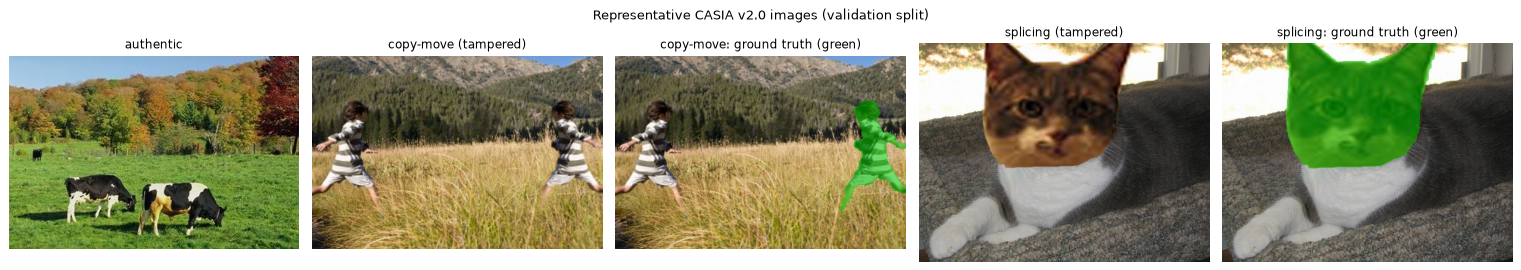

copy-move example: CASIA2/Tp/Tp_S_CND_S_B_cha00088_cha00088_10179.tif 
splicing example : CASIA2/Tp/Tp_D_CRD_S_O_ani10111_ani10103_10635.jpg


In [2]:
df = read_manifest(cfg).merge(read_splits(cfg), on="path")
kind = np.where(df.label == 0, "authentic", df.forgery_type)
display(pd.crosstab(kind, df.format, margins=True).rename_axis(index="class", columns="file format"))

val = df[df.split == "val"]
au_ex = val[val.label == 0].sort_values("path").iloc[5]
cm_ex = val[(val.forgery_type == "copy-move") & val.mask_valid & val.tampered_frac.between(0.05, 0.25)].sort_values("path").iloc[3]
sp_ex = val[(val.forgery_type == "splicing") & val.mask_valid & val.tampered_frac.between(0.05, 0.25)].sort_values("path").iloc[3]

def gt_overlay(r):
    im = load_rgb(resolve(r.path))
    return E.overlay(im, load_mask(resolve(r.mask_path)), color=(0, 200, 0))

show([load_rgb(resolve(au_ex.path)), load_rgb(resolve(cm_ex.path)), gt_overlay(cm_ex),
      load_rgb(resolve(sp_ex.path)), gt_overlay(sp_ex)],
     ["authentic", "copy-move (tampered)", "copy-move: ground truth (green)", "splicing (tampered)",
      "splicing: ground truth (green)"], suptitle="Representative CASIA v2.0 images (validation split)", width=3.6)
print("copy-move example:", cm_ex.path, "\nsplicing example :", sp_ex.path)

**An important finding about the dataset.** The table above shows that authentic images are never TIFF, while most tampered images are. In addition, 89 % of the authentic JPEGs use the standard IJG quantisation tables, which no tampered JPEG uses.

A classifier given only the **file metadata reaches 0.990 balanced accuracy**, without looking at a single pixel. Results on the raw files would therefore be inflated.

**Stage 0 (preprocessing protocol R):** every image is downscaled ×0.75 and re-saved as JPEG Q85 before analysis. This removes the file-format cues, so only image-content evidence counts. All results below use protocol R unless stated otherwise.

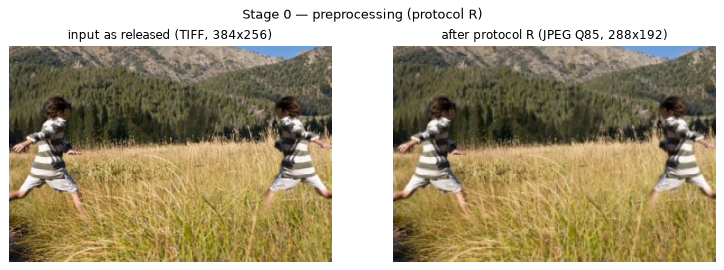

In [3]:
img_cm = apply_protocol(load_rgb(resolve(cm_ex.path)), "R", cfg)
img_sp = apply_protocol(load_rgb(resolve(sp_ex.path)), "R", cfg)
gt_cm = protocol_mask(load_mask(resolve(cm_ex.mask_path)), "R", cfg)
gt_sp = protocol_mask(load_mask(resolve(sp_ex.mask_path)), "R", cfg)
raw = load_rgb(resolve(cm_ex.path))
show([raw, img_cm], [f"input as released ({cm_ex.format}, {raw.shape[1]}x{raw.shape[0]})",
                     f"after protocol R (JPEG Q85, {img_cm.shape[1]}x{img_cm.shape[0]})"],
     suptitle="Stage 0 — preprocessing (protocol R)", width=4.6)

## 3. Implementation of the processing stages (before and after)

We implemented techniques from **all five project categories**, as planned in the proposal:
- 3.1 point processing
- 3.2 histogram processing
- 3.3 spatial filtering
- 3.4 frequency domain
- 3.5 edge and corner detection

Each figure shows the **input**, the **processed output(s)** and their titles. The examples are the copy-move image (the person on the right is a mirrored copy of the one on the left) and the splicing image shown above. Bright colours in the heat maps mean "more suspicious".

### 3.1 Point processing — Error Level Analysis (ELA)
ELA re-saves the image as JPEG and takes the per-pixel absolute difference, **|I − JPEG_q(I)|**, a point operation on every pixel. A region pasted in after the original compression re-compresses at a different error level. Busy texture also produces large errors, so we divide the 8×8 block ELA by the block's texture (standard deviation + c).

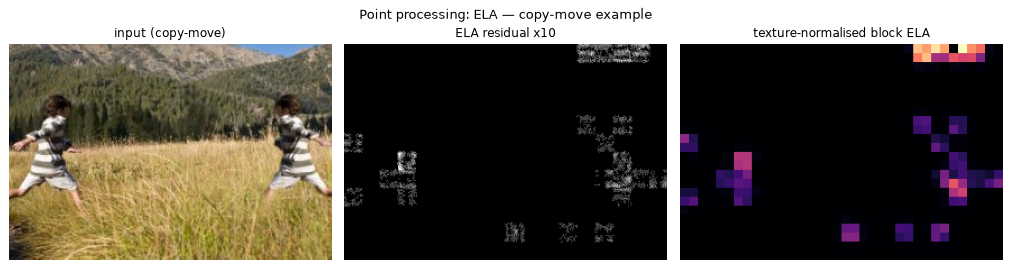

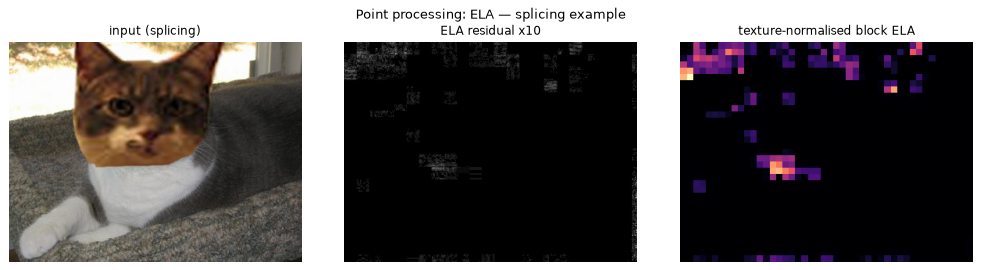

In [4]:
ela = module("ela")
for name, im in (("copy-move", img_cm), ("splicing", img_sp)):
    m = ela.maps(im)
    show([im, np.clip(m["residual"] * 10, 0, 255), up(np.where(m["valid"], m["norm_block"], 0), im.shape)],
         [f"input ({name})", "ELA residual x10", "texture-normalised block ELA"],
         [None, "gray", "magma"], suptitle=f"Point processing: ELA — {name} example")

### 3.2 Histogram processing — histogram equalisation and patch-histogram χ²
The raw ELA residual is low-contrast: almost all pixels are 0–2. **Histogram equalisation** spreads it over the full range. We then compare each 16×16 patch's histogram with the image's typical patch histogram using the **χ² distance**. Patches whose error distribution differs stand out.

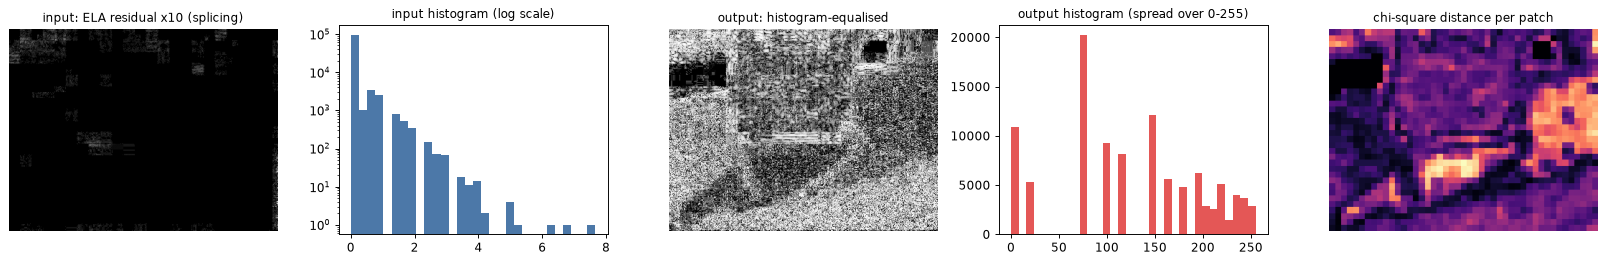

In [5]:
hist = module("histogram")
hm = hist.maps(img_sp)
resid = ela.maps(img_sp)["residual"]
fig, ax = plt.subplots(1, 5, figsize=(19, 3.2))
ax[0].imshow(np.clip(resid * 10, 0, 255), cmap="gray"); ax[0].set_title("input: ELA residual x10 (splicing)")
ax[1].hist(resid.ravel(), bins=30, color="#4C78A8"); ax[1].set_yscale("log"); ax[1].set_title("input histogram (log scale)")
ax[2].imshow(hm["equalized"], cmap="gray"); ax[2].set_title("output: histogram-equalised")
ax[3].hist(hm["equalized"].ravel(), bins=32, color="#E45756"); ax[3].set_title("output histogram (spread over 0-255)")
ax[4].imshow(up(np.where(hm["valid"], hm["distance"], 0), img_sp.shape), cmap="magma"); ax[4].set_title("chi-square distance per patch")
for a in (ax[0], ax[2], ax[4]): a.axis("off")
plt.tight_layout(); plt.show()

### 3.3 Spatial filtering — local noise level
A spliced region usually comes from a different camera and carries a different noise level. A **high-pass filter** removes the image content and leaves mostly noise. We use Immerkær's 3×3 noise-estimation kernel, compared with the proposal's 3×3 Laplacian in Section 4. A robust noise σ is then estimated per 8×8 block, using only non-edge pixels, because edges leak content into the residual.

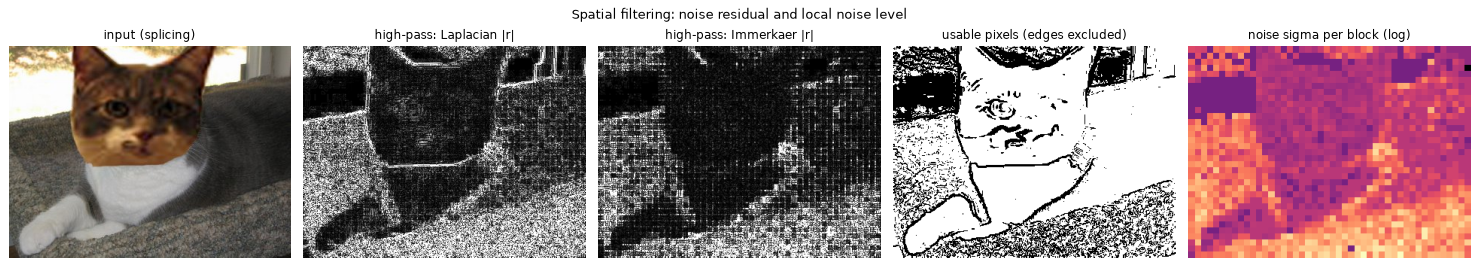

In [6]:
noise = module("noise")
nm = noise.maps(img_sp)
lap = module("noise", kernel="laplacian").maps(img_sp)
show([img_sp, np.clip(np.abs(lap["residual"]), 0, 30), np.clip(np.abs(nm["residual"]), 0, 30), nm["usable"], up(nm["log_sigma"], img_sp.shape)],
     ["input (splicing)", "high-pass: Laplacian |r|", "high-pass: Immerkaer |r|", "usable pixels (edges excluded)", "noise sigma per block (log)"],
     [None, "gray", "gray", "gray", "magma"], suptitle="Spatial filtering: noise residual and local noise level", width=3.5)

### 3.4 Frequency domain — DCT double quantisation and JPEG ghosts
JPEG quantises the 8×8 **DCT** coefficients, so a coefficient's histogram concentrates on multiples of the quantisation step. When an image is compressed **twice**, the histogram develops a periodic pattern of peaks and gaps; a region pasted in after the first compression does not follow it.

The first figure demonstrates this effect on an authentic image (single vs double compression). The second shows the DCT double-quantisation evidence map and the **JPEG-ghost** map, which re-saves the image at qualities 50–95 and looks for regions whose error curve differs, on the copy-move example.

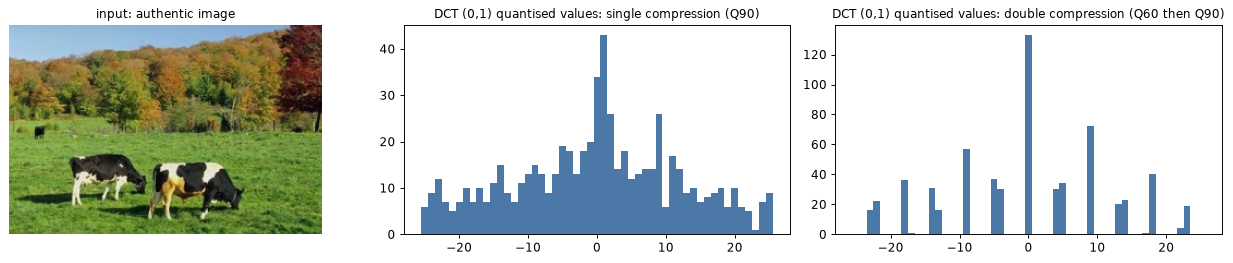

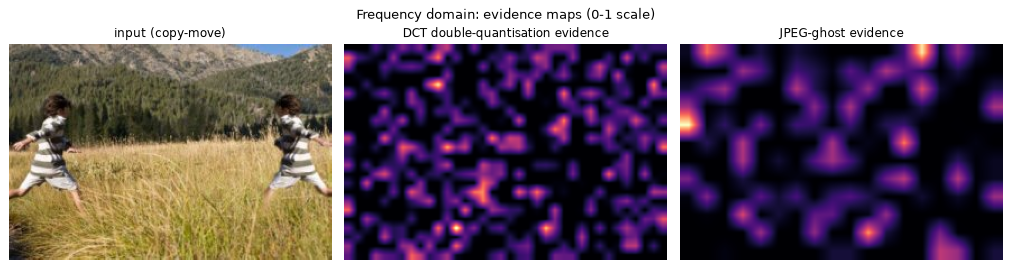

In [7]:
base = resample(load_rgb(resolve(au_ex.path)), 0.75)            # erase the original JPEG grid
single = jpeg_roundtrip(base, 90)
double = jpeg_roundtrip(jpeg_roundtrip(base, 60), 90)
step = ijg_table(90).reshape(8, 8)[0, 1]                       # quantisation step of DCT coefficient (0,1) at Q90

def dct_index(im):
    Y = cv2.cvtColor(im, cv2.COLOR_RGB2YCrCb)[..., 0].astype(np.float32) - 128
    h, w = (Y.shape[0] // 8) * 8, (Y.shape[1] // 8) * 8
    c = np.array([cv2.dct(Y[i:i + 8, j:j + 8])[0, 1] for i in range(0, h, 8) for j in range(0, w, 8)])
    return np.rint(c / step)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
ax[0].imshow(base); ax[0].set_title("input: authentic image"); ax[0].axis("off")
for a, im, t in ((ax[1], single, "single compression (Q90)"), (ax[2], double, "double compression (Q60 then Q90)")):
    v = dct_index(im); v = v[np.abs(v) <= 25]
    a.hist(v, bins=np.arange(-25.5, 26.5), color="#4C78A8"); a.set_title(f"DCT (0,1) quantised values: {t}")
plt.tight_layout(); plt.show()

dq, gh = module("dct_dq").extract(img_cm), module("jpeg_ghost").extract(img_cm)
show([img_cm, dq.evidence_map, gh.evidence_map], ["input (copy-move)", "DCT double-quantisation evidence", "JPEG-ghost evidence"],
     [None, "magma", "magma"], suptitle="Frequency domain: evidence maps (0-1 scale)")

**Observation:** single compression gives a smooth histogram, while double compression produces the regular comb of peaks and gaps that the DCT module tests for, using a permutation test for periodicity.

### 3.5 Edge and corner detection — edge sharpness and copy-move keypoints
- **Edge sharpness:** **Canny** finds edges, and at each edge pixel we measure sharpness (gradient ÷ local contrast). A pasted object can have unnaturally hard or feathered boundaries.
- **Copy-move:** **keypoints** (SIFT, compared with the proposal's Harris corners in Section 4) are matched against the image itself **and its mirror image**. The matches are then verified with **RANSAC**, so only pairs explained by one consistent geometric transform survive. This finds duplicated regions, including flipped copies like this one.

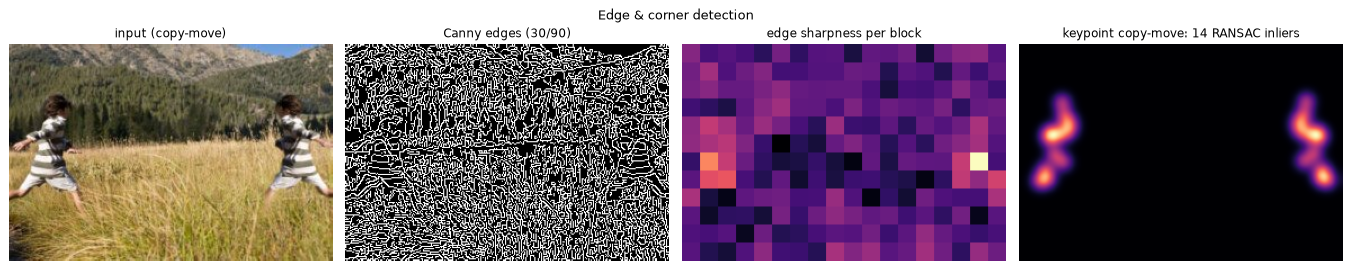

In [8]:
em = module("edges").maps(img_cm)
kp = module("cm_keypoint").extract(img_cm)
show([img_cm, em["edges"], up(em["block_sharpness"], img_cm.shape), kp.evidence_map],
     ["input (copy-move)", "Canny edges (30/90)", "edge sharpness per block",
      f"keypoint copy-move: {int(kp.features['local_n_inliers'])} RANSAC inliers"],
     [None, "gray", "magma", "magma"], suptitle="Edge & corner detection")

### 3.6 Combining the stages
The eight evidence maps and their 82 summary features are combined:
- **Decision:** a random forest, compared with an SVM in Section 6, turns the features into P(tampered).
- **Region:** gradient boosting fuses the maps on 8×8 cells into a suspected-region mask.

Below are the results of the combined pipeline on the two examples.

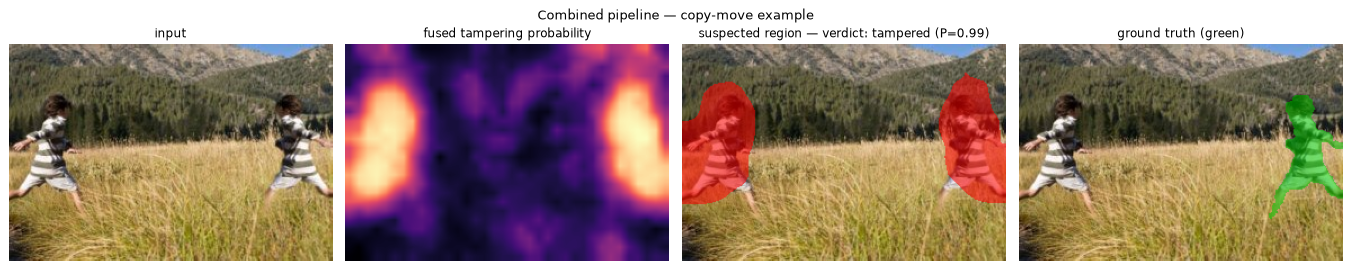

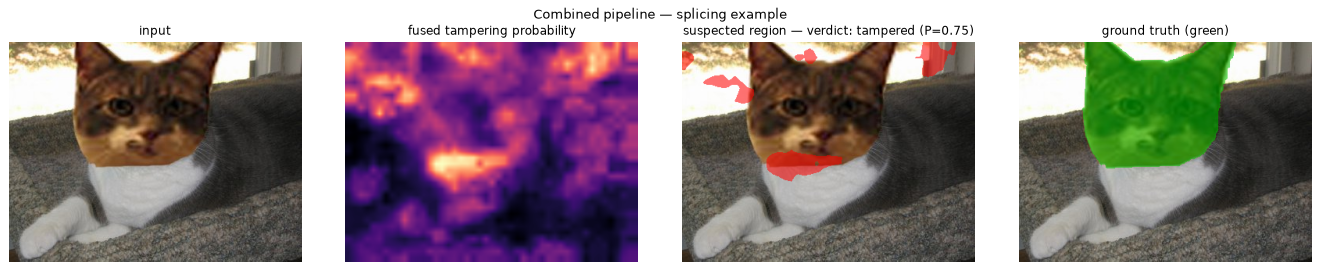

Note: validation images were used to fit the final models, so these two results are optimistic.


In [9]:
M = E.load_models("R")
for name, r, im, gt in (("copy-move", cm_ex, img_cm, gt_cm), ("splicing", sp_ex, img_sp, gt_sp)):
    res = E.analyse(resolve(r.path), M, cfg)
    show([im, res.maps["fused"], E.overlay(im, res.mask), E.overlay(im, gt, color=(0, 200, 0))],
         ["input", "fused tampering probability", f"suspected region — verdict: {res.verdict} (P={res.confidence:.2f})",
          "ground truth (green)"], [None, "magma", None, None], suptitle=f"Combined pipeline — {name} example")
print("Note: validation images were used to fit the final models, so these two results are optimistic.")

**Observation:**
- **Copy-move example:** the decision is correct (tampered, P = 0.99). The marked region covers **both** the original and the mirrored copy, as expected from copy-move matching. The ground truth marks only the pasted copy.
- **Splicing example:** the decision is also correct (tampered, P = 0.75), but the marked region is **wrong**: it highlights the dark neck area instead of the pasted cat face.
- **Why:** splices whose donor photo has a similar compression and noise history leave little local evidence. This is the main weakness we are working on (Section 8).

## 4. Parameter experimentation

Each technique's parameters were tuned **on training/validation images only**. We fitted on 2,400 training images and scored 1,000 validation images, changing one parameter at a time and keeping the others fixed. Every tested setting was scored with two objective numbers:
- **image AUC:** how well the technique's features alone separate tampered from authentic images. 0.5 is chance and 1.0 is perfect.
- **pixel AUC:** how well its evidence map ranks tampered pixels above untampered ones, against the ground-truth masks.

The setting with the best **mean of the two** was kept. For each technique we show the setting visually on our example, then the scores of every tested value.

### 4.1 ELA — re-save quality q

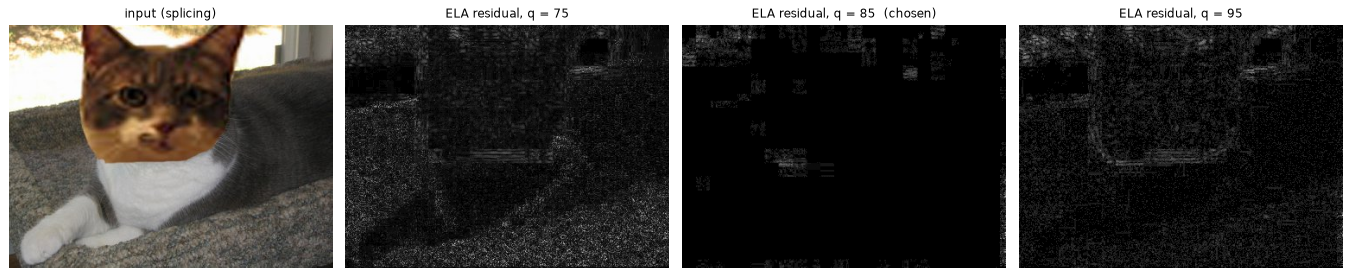

,param,value,image AUC,pixel AUC,score (mean)
0,quality,75,0.684,0.548,0.616
1,quality,85,0.690,0.613,0.651
2,quality,90,0.701,0.551,0.626
3,quality,95,0.698,0.581,0.639
4,texture_c,1.0,0.689,0.612,0.650
5,texture_c,4.0,0.690,0.613,0.651
6,texture_c,16.0,0.696,0.615,0.656


In [10]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
ax[0].imshow(img_sp); ax[0].set_title("input (splicing)"); ax[0].axis("off")
for a, q in zip(ax[1:], (75, 85, 95)):
    a.imshow(np.clip(module("ela", quality=q).maps(img_sp)["residual"] * 10, 0, 255), cmap="gray")
    a.set_title(f"ELA residual, q = {q}" + ("  (chosen)" if q == 85 else "")); a.axis("off")
plt.tight_layout(); plt.show()
display(sweep("ela", "quality", "texture_c"))

**Which worked better, and why:**
- **Quality:** q = **85** gives the best localisation, with pixel AUC 0.613 against 0.548 at q = 75 and 0.581 at q = 95.
  - **Too low a quality** (75) produces large errors everywhere, so the tampered region no longer stands out.
  - **Too high a quality** (95) produces almost no error at all.
  - The proposal suggested q ≈ 90. That setting was slightly better for image AUC (0.701) but much worse for localisation (0.551), so we changed it.
- **Texture constant:** stronger texture normalisation (c = 16) added a small gain (0.651 → 0.656), because busy regions are less often mistaken for tampering.

### 4.2 Histogram processing — patch size (proposal: 32×32)

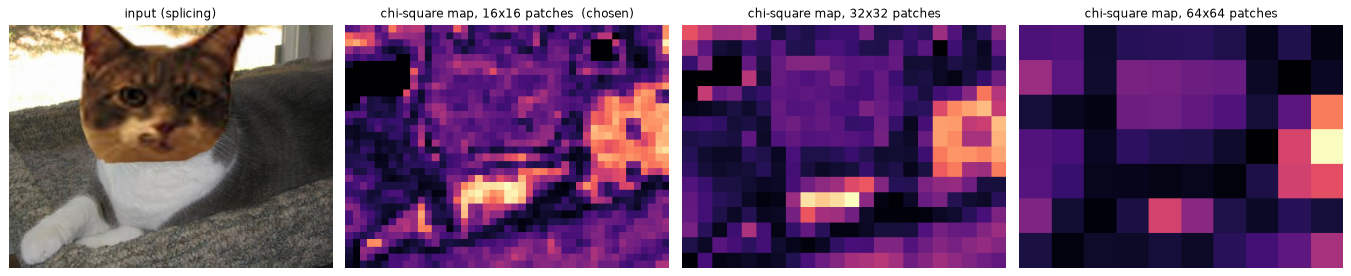

,param,value,image AUC,pixel AUC,score (mean)
0,quality,75,0.566,0.580,0.573
1,quality,90,0.526,0.571,0.548
2,quality,95,0.531,0.574,0.553
3,patch,16,0.571,0.589,0.580
4,patch,32,0.566,0.580,0.573
5,patch,64,0.558,0.532,0.545
6,bins,8,0.559,0.593,0.576
7,bins,16,0.571,0.589,0.580
8,bins,32,0.556,0.588,0.572


In [11]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
ax[0].imshow(img_sp); ax[0].set_title("input (splicing)"); ax[0].axis("off")
for a, p in zip(ax[1:], (16, 32, 64)):
    m = module("histogram", patch=p).maps(img_sp)
    a.imshow(up(np.where(m["valid"], m["distance"], 0), img_sp.shape), cmap="magma")
    a.set_title(f"chi-square map, {p}x{p} patches" + ("  (chosen)" if p == 16 else "")); a.axis("off")
plt.tight_layout(); plt.show()
display(sweep("histogram", "patch", "bins", "quality"))

**Which worked better, and why:**
- **Patch size:** **16×16** patches beat the proposed 32×32 (score 0.580 vs 0.573) and 64×64 (0.545). CASIA's tampered regions are small, a median of about 3 % of the image. Larger patches mix tampered and untampered pixels, which dilutes the χ² difference and blurs the map.
- **Bins:** 16 histogram bins worked best.
- **Re-save quality:** Q75 worked best.

### 4.3 Spatial filtering — high-pass kernel (proposal: 3×3 Laplacian) and edge exclusion

In [12]:
display(sweep("noise", "kernel", "block", "edge_quantile", "min_std"))

,param,value,image AUC,pixel AUC,score (mean)
0,kernel,laplacian,0.598,0.468,0.533
1,kernel,immerkaer,0.640,0.491,0.566
2,block,8,0.640,0.491,0.566
3,block,16,0.558,0.554,0.556
4,edge_quantile,0.4,0.635,0.462,0.548
5,edge_quantile,0.6,0.640,0.491,0.566
6,edge_quantile,0.8,0.606,0.547,0.577
7,min_std,0.5,0.579,0.546,0.562
8,min_std,1.0,0.606,0.547,0.577
9,min_std,2.0,0.609,0.560,0.584


**Which worked better, and why:**
- **Kernel:** Immerkær's kernel clearly beats the Laplacian (image AUC 0.640 vs 0.598). It is designed to cancel image structure (edges, ramps) and leave noise, while the Laplacian responds strongly to edges. In Section 3.3 the Laplacian residual still shows object outlines.
- **Edge exclusion and minimum texture:** excluding the strongest 20 % of gradients (edge quantile 0.8) and skipping near-flat blocks (min std 2) improved localisation (pixel AUC 0.491 → 0.560). Without them, edges and flat sky dominate the noise map.
- **Block size:** we kept 8×8 blocks. 16×16 localised slightly better but was much weaker at the image level.

### 4.4 Frequency domain — DCT significance level α and number of frequencies

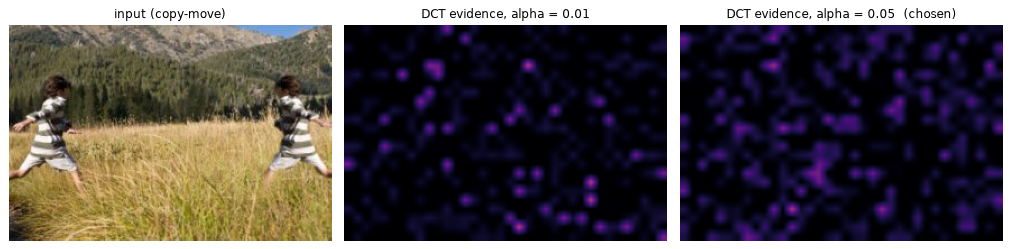

,param,value,image AUC,pixel AUC,score (mean)
0,n_freq,3,0.671,0.603,0.637
1,n_freq,6,0.782,0.623,0.703
2,n_freq,9,0.796,0.630,0.713
3,n_freq,15,0.793,0.647,0.720
4,alpha,0.001,0.500,0.500,0.500
5,alpha,0.01,0.793,0.647,0.720
6,alpha,0.05,0.797,0.668,0.733


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].imshow(img_cm); ax[0].set_title("input (copy-move)"); ax[0].axis("off")
for a, al in zip(ax[1:], (0.01, 0.05)):
    a.imshow(module("dct_dq", alpha=al).extract(img_cm).evidence_map, cmap="magma", vmin=0, vmax=1)
    a.set_title(f"DCT evidence, alpha = {al}" + ("  (chosen)" if al == 0.05 else "")); a.axis("off")
plt.tight_layout(); plt.show()
display(sweep("dct_dq", "n_freq", "alpha"))

**Which worked better, and why:**
- **Frequencies:** using the **15** lowest AC frequencies gave the best score (0.720), well above 3 frequencies (0.637). Low frequencies carry most of the coefficients, but more of them make the periodicity test more reliable.
- **Significance level:** α = **0.05** was best (0.733). At α = 0.001 the test never fires (score 0.500, chance).
- **Under protocol R:** the DCT test is weak, because resampling destroys the original 8×8 grid that double quantisation needs. See Section 5.

### 4.5 Edge detection — Canny thresholds (proposal: 50/150)

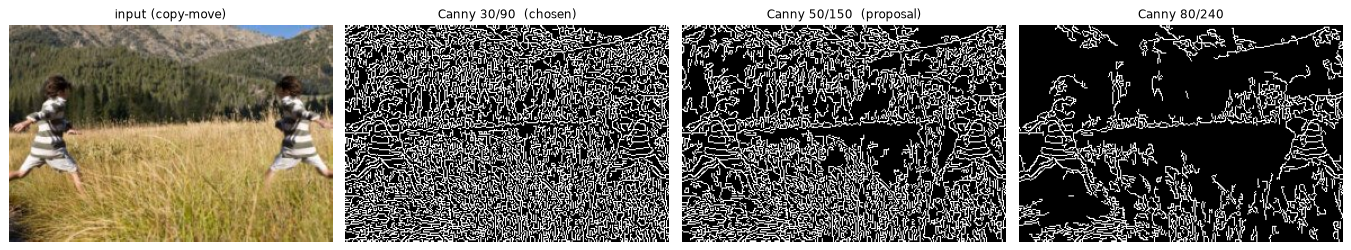

,param,value,image AUC,pixel AUC,score (mean)
0,low,30,0.610,0.574,0.592
1,low,50,0.547,0.586,0.567
2,low,80,0.545,0.594,0.569
3,block,16,0.610,0.574,0.592
4,block,32,0.568,0.554,0.561


In [14]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
ax[0].imshow(img_cm); ax[0].set_title("input (copy-move)"); ax[0].axis("off")
for a, (lo, hi) in zip(ax[1:], ((30, 90), (50, 150), (80, 240))):
    a.imshow(module("edges", low=lo, high=hi).maps(img_cm)["edges"], cmap="gray")
    a.set_title(f"Canny {lo}/{hi}" + ("  (chosen)" if lo == 30 else "  (proposal)" if lo == 50 else "")); a.axis("off")
plt.tight_layout(); plt.show()
display(sweep("edges", "low", "block"))

**Which worked better, and why:**
- **Thresholds:** lower thresholds (**30/90**) scored better than the proposed 50/150 (0.592 vs 0.567). The images are small, and after protocol R their edges are softer, so the higher thresholds miss many object boundaries, including those of pasted objects.
- **Unwanted effect:** lower thresholds also pick up more grass and texture edges, which slightly lowers pixel AUC. The combined score still favours 30/90.

### 4.6 Copy-move matching — Harris corners (proposal) vs SIFT keypoints

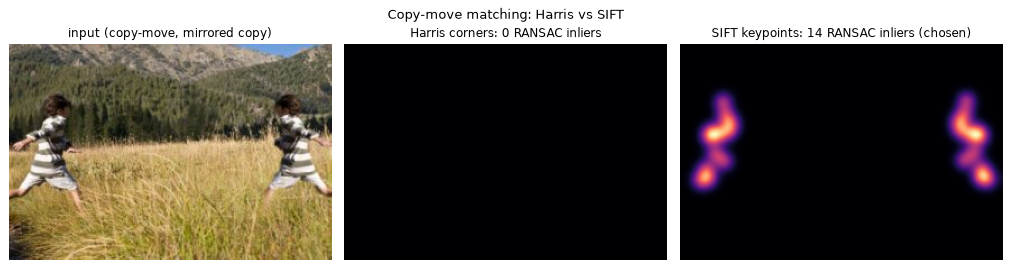

,param,value,image AUC,pixel AUC,score (mean)
0,detector,harris,0.564,0.512,0.538
1,detector,sift,0.744,0.719,0.731
2,ratio,0.5,0.743,0.702,0.723
3,ratio,0.6,0.744,0.719,0.731
4,ratio,0.7,0.706,0.751,0.728
5,contrast,0.005,0.734,0.723,0.729
6,contrast,0.01,0.744,0.719,0.731
7,contrast,0.04,0.722,0.687,0.704


In [15]:
kh = module("cm_keypoint", detector="harris").extract(img_cm)
ks = module("cm_keypoint", detector="sift").extract(img_cm)
show([img_cm, kh.evidence_map, ks.evidence_map],
     ["input (copy-move, mirrored copy)", f"Harris corners: {int(kh.features['local_n_inliers'])} RANSAC inliers",
      f"SIFT keypoints: {int(ks.features['local_n_inliers'])} RANSAC inliers (chosen)"], [None, "magma", "magma"],
     suptitle="Copy-move matching: Harris vs SIFT")
display(sweep("cm_keypoint", "detector", "ratio", "contrast"))

**Which worked better, and why:** **SIFT** far outperforms the proposed Harris corners:
- image AUC 0.744 vs 0.564;
- pixel AUC 0.719 vs 0.512.

On CASIA's small images, Harris yields few corners, and they are not repeatable when the copy is rotated, scaled or mirrored. SIFT is scale- and rotation-invariant and comes with a descriptor for matching. A matching ratio of 0.6 was the best balance: 0.7 localises a little better but admits more false matches. Harris is therefore reported as a **negative result** and replaced.

### 4.7 Summary of parameter decisions

| Technique | Proposal | Tested | Chosen | Reason |
|---|---|---|---|---|
| ELA re-save quality | ≈ 90 | 75, 85, 90, 95 | **85** | best localisation (pixel AUC 0.613) |
| Histogram patch size | 32×32 | 16, 32, 64 | **16×16** | small tampered regions |
| Noise high-pass filter | 3×3 Laplacian | Laplacian, Immerkær | **Immerkær** | cancels edges, keeps noise |
| DCT test level / frequencies | — | α 0.001–0.05; 3–15 freq. | **α 0.05, 15** | most reliable periodicity test |
| Canny thresholds | 50/150 | 30/90, 50/150, 80/240 | **30/90** | soft edges after resampling |
| Copy-move detector | Harris | Harris, SIFT | **SIFT** | invariant, repeatable keypoints |

## 5. Preliminary analysis

Each step is assessed visually (Section 3) and with two numbers measured under protocol R by 5-fold cross-validation on the 10,722 development images:
- **alone:** the AUC of the step's features on their own;
- **drop if removed:** how much the AUC of the full pipeline falls when the step is left out.

In [16]:
ab = pd.read_csv(resolve("results/phase5/ablations.csv"))
r = ab[ab.protocol == "R"]
alone = r[r.variant == "module alone"].set_index("module").auc
drop = r[r.variant == "leave one out"].set_index("module").drop_vs_all
names = {"ela": "ELA (point)", "jpeg_ghost": "JPEG ghosts (point/frequency)", "histogram": "Patch histograms (histogram)",
         "noise": "Noise level (spatial)", "dct_dq": "DCT double quantisation (frequency)", "edges": "Edge sharpness (edge)",
         "cm_keypoint": "SIFT copy-move (corner)", "cm_block": "DCT-block copy-move (frequency)"}
tab = pd.DataFrame({"AUC alone": alone, "drop if removed": drop}).loc[list(names)].rename(index=names)
display(tab.round(3))
print(f"all eight stages together: AUC {r[r.variant == 'all modules'].auc.iloc[0]:.3f}")

,AUC alone,drop if removed
module,,
ELA (point),0.664,0.013
JPEG ghosts (point/frequency),0.624,0.001
Patch histograms (histogram),0.566,-0.001
Noise level (spatial),0.617,0.004
DCT double quantisation (frequency),0.519,0.001
Edge sharpness (edge),0.605,0.002
SIFT copy-move (corner),0.720,0.080
DCT-block copy-move (frequency),0.579,0.003


all eight stages together: AUC 0.795


| Step | What changed in the image? | Did it improve the desired feature? | Unwanted effects | Decision |
|---|---|---|---|---|
| **Stage 0 · Protocol R** | Image downscaled and re-saved; the file format no longer differs between classes | Yes: removes the label leak (shortcut accuracy 0.990 → 0.649), so results are honest | Also weakens genuine compression traces (DCT, ghosts) | **Keep** (essential) |
| **ELA** | Areas that re-compress differently light up | Yes: alone AUC 0.664; removing it costs 0.013, the second-largest loss | Edges and texture also produce error | **Keep**, with texture normalisation |
| **Histogram equalisation + χ²** | The faint ELA residual becomes visible; odd patches stand out | Weak alone (0.566); adds almost nothing on top of ELA (−0.001) | Equalisation also amplifies noise in flat areas | **Keep for visualisation; modify** (low weight) |
| **Noise level** | Content removed by the high-pass filter; σ map per block | Moderate: alone 0.617, removing it costs 0.004; most useful for splicing | Edges leak into the residual; flat areas have no noise | **Keep**, with edge and flat-area masking |
| **DCT double quantisation** | Periodic DCT pattern tested per frequency | Strong under re-encoding only (B); near chance under R (0.519) | Resampling destroys the 8×8 grid it relies on | **Keep, modify:** fixed false-positive rate; mainly useful for JPEG-only inputs |
| **JPEG ghosts** | Re-save curves compared per block | Moderate: alone 0.624 under R (0.758 under B) | Coarse 16×16 blocks blur small regions | **Keep** |
| **Canny edge sharpness** | Edge map and per-block sharpness | Moderate: alone 0.605, removing it costs 0.002 | Texture (grass, foliage) creates many edges | **Keep** |
| **SIFT copy-move (+RANSAC)** | Duplicated regions matched, including mirrored copies | **Strongest step:** alone 0.720; removing it costs 0.080 | False alarms on genuinely repeated structures (columns, windows) | **Keep** (core) |
| **DCT-block copy-move** | Block shifts voted | Weak alone (0.579); small gain (0.003) | Misses rotated or scaled copies | **Keep** as a complement to SIFT |
| **Harris corners** (proposal) | Few, unstable corners | No (0.564 alone, Section 4.6) | — | **Removed**, replaced by SIFT |

**Overall:** no single technique is enough, but together they reach AUC 0.795 under the strict protocol. Copy-move matching and ELA carry most of the signal. The weakest steps (histogram χ², and DCT under R) are kept because they cost little and help in other settings, but they are candidates for removal in the final pipeline.

## 6. Preliminary evaluation

Three objective comparisons, all on the **development data** (cross-validation and validation). The held-out test split is reserved for the final evaluation.

### 6.1 Does each technique help? (image-level AUC of each stage alone, protocol R)

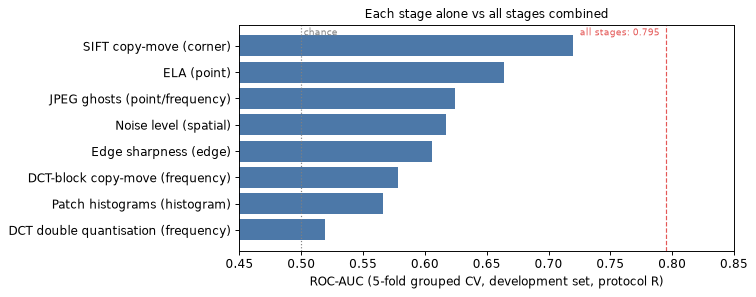

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.6))
t = tab.sort_values("AUC alone")
ax.barh(t.index, t["AUC alone"], color="#4C78A8")
ax.axvline(0.5, color="grey", ls=":", lw=1); ax.text(0.502, len(t) - 0.6, "chance", color="grey", fontsize=8)
ax.axvline(0.795, color="#E45756", ls="--", lw=1); ax.text(0.79, len(t) - 0.6, "all stages: 0.795", color="#E45756", fontsize=8, ha="right")
ax.set_xlim(0.45, 0.85); ax.set_xlabel("ROC-AUC (5-fold grouped CV, development set, protocol R)")
ax.set_title("Each stage alone vs all stages combined"); plt.tight_layout(); plt.show()

### 6.2 Do the forensic techniques beat the dataset shortcuts? (classifier comparison, RF vs SVM)

In [18]:
r5 = pd.read_csv(resolve("results/phase5/results.csv"))
sel = r5[r5.feature_set.isin(["shortcuts", "forensic_all", "forensic+shortcuts"]) & r5.protocol.isin(["R", "B"])]
display(sel.pivot_table(index="feature_set", columns=["protocol", "model"], values="roc_auc_mean")
          .rename(index={"shortcuts": "shortcut features only", "forensic_all": "our 8 techniques",
                         "forensic+shortcuts": "techniques + shortcuts"}).round(3))
av = pd.read_csv(resolve("results/phase5/added_value.csv"))
row = av[(av.protocol == "R") & (av.model == "rf") & (av.comparison == "forensic+shortcuts - shortcuts")].iloc[0]
print(f"Added value of our techniques over the shortcuts (R, random forest): +{row.delta_auc:.3f} "
      f"(95% CI {row.ci_low:.3f} to {row.ci_high:.3f})")

protocol                    B             R       
model                      rf    svm     rf    svm
feature_set                                       
techniques + shortcuts  0.926  0.922  0.810  0.826
our 8 techniques        0.910  0.892  0.795  0.793
shortcut features only  0.876  0.876  0.721  0.771

Added value of our techniques over the shortcuts (R, random forest): +0.088 (95% CI 0.078 to 0.097)


Under the strict protocol R, our eight techniques reach **AUC 0.795**, against 0.721 for the shortcut features. Added on top of the shortcuts they gain **+0.088** (95 % CI 0.078–0.097), so they carry genuine tampering evidence. The random forest and the SVM perform similarly on the forensic features (0.795 vs 0.793).

### 6.3 Localisation: does fusing the maps beat any single map? (validation images, protocol R)

In [19]:
lm = pd.read_csv(resolve("results/phase6/methods_R.csv"))
keep = ["hgb", "mean", "single:cm_keypoint", "single:ela", "single:noise", "single:edges", "single:histogram", "whole"]
lab = {"hgb": "learned fusion (gradient boosting)", "mean": "average of the 8 maps", "whole": "mark whole image (baseline)"}
lm = lm[lm.method.isin(keep)].set_index("method").loc[keep]
lm.index = [lab.get(m, m.replace("single:", "single map: ")) for m in lm.index]
display(lm[["f1", "iou", "pixel_auc"]].rename(columns={"f1": "pixel F1", "iou": "IoU", "pixel_auc": "pixel AUC"}).round(3))

,pixel F1,IoU,pixel AUC
learned fusion (gradient boosting),0.185,0.119,0.695
average of the 8 maps,0.159,0.099,0.671
single map: cm_keypoint,0.152,0.102,0.620
single map: ela,0.128,0.076,0.624
single map: noise,0.132,0.082,0.555
single map: edges,0.127,0.078,0.573
single map: histogram,0.133,0.084,0.560
mark whole image (baseline),0.136,0.086,NaN


The learned fusion gives the best localisation: **pixel F1 0.185 and IoU 0.119**, against 0.159 for a simple average and 0.152 for the best single map (SIFT copy-move). Absolute scores are modest because CASIA's tampered regions are small, with a median of 3 % of the image. Localisation is the main area to improve.

## 7. Updated pipeline

```
input image
  |
  v
0. Preprocessing (protocol R): downscale x0.75, JPEG Q85      [NEW]
  |
  +--> 1. Point:     ELA (q=85) + JPEG ghosts                 [ghosts NEW]
  +--> 2. Histogram: equalised ELA -> chi2 of 16x16 patches   [was 32x32]
  +--> 3. Spatial:   Immerkaer high-pass -> noise sigma map   [was Laplacian]
  +--> 4. Frequency: DCT double quantisation + DCT-block copy-move
  +--> 5. Edge/corner: Canny 30/90 + SIFT copy-move, RANSAC   [was Harris]
  v
6. Features: within-image inconsistency statistics (82)
  |
  +--> 7a. Decision: random forest -> calibration ->
  |        tampered / authentic / UNCERTAIN
  +--> 7b. Region: fusion of the 8 maps -> suspected mask
```

| Change from the Phase 1 proposal | Reason |
|---|---|
| **Added Stage 0 (protocol R)** | The dataset leaks its labels through file format; without this step the results would be inflated |
| **Harris → SIFT** for copy-move, plus **mirror matching** and RANSAC | Harris failed on small images; some copies are mirrored |
| **Laplacian → Immerkær kernel**, with edge masking | The Laplacian responds to edges, not only to noise |
| **32×32 → 16×16** histogram patches; **Canny 50/150 → 30/90** | Better scores in the parameter experiments |
| **Added JPEG ghosts** and DCT-block copy-move | Extra evidence for compression history and duplication |
| **Within-image features** rather than global statistics | Global statistics mostly measure the file format (shortcut) |
| **Added an "uncertain" verdict** | The detector abstains when the evidence is weak, rather than guessing |

## 8. Next steps

**What still needs to be completed (Phase 3):**
- **Final results:** the final held-out test evaluation and the robustness and cross-dataset experiments. These have been run once with the frozen pipeline, and the results will be presented in the final report, without further tuning.
- **Write-up:** the final IEEE-format report and the presentation.
- **Demonstration:** the interactive tool for analysing new photos, with explanations of each verdict.
- **Optional deep-learning extension:** an ELA + CNN baseline, compared with the classical pipeline under the same protocols. It is implemented, and its results are reserved for the final report.

**Problems and challenges encountered:**
- **The dataset leak:** file format and JPEG tables alone predict the label (0.990 balanced accuracy). We had to redesign the evaluation (protocol R and shortcut baselines), which lowered the headline numbers but made them honest.
- **Data quality:** 142 misnamed masks, 19 unusable masks and 99 inconsistent type labels had to be repaired. Near-duplicate images had to be kept within one split.
- **Bugs found and fixed:**
  - The DCT periodicity test had 16–48 % false positives, fixed with a permutation test.
  - The noise module treated flat patches as outliers.
  - Copy-move matching missed mirrored copies.
- **Splicing is hard:** splices between photos with the same processing history leave little compression, noise or edge inconsistency.
- **False alarms:** genuinely repeated structures (columns, windows, patterns) can look like copy-moves.

**What we plan to improve before Phase 3:**
- **Localisation:** improve it for small regions, which are below 1 % of the image in about a fifth of the dataset.
- **Copy-move false alarms:** reduce them on self-similar scenes.
- **Robustness:** test against re-compression, resizing, blur, noise and social-media-style uploads, and on a second dataset (MICC-F220).
- **Final pipeline:** decide whether the weakest steps (histogram χ², and DCT under resampling) stay.